<a href="https://colab.research.google.com/github/hamagami/IS2026/blob/main/04_Seq2Seq.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Seq2Seq: 系列反転で学ぶTeacher Forcing / Seq2Seq: Teacher forcing through sequence reversal



## 目的 / Objective
LSTM Encoderの最終 $(h,c)$ をDecoderへ渡します．学習時は正解の前トークン，生成時は直前の自分の予測を入力します．翻訳器ではなく，構造を観察するための人工課題です．入力3〜7桁，出力は逆順の数字＋EOSです．

Pass the final LSTM encoder states $(h,c)$ to the decoder. Training uses the previous correct token; generation uses the previous prediction. This synthetic task illustrates the architecture rather than translation. Inputs contain 3–7 digits; targets are the reversed digits followed by EOS.


## 準備 / Setup


In [ ]:
import sys, subprocess, importlib.util
# Colabの既存PyTorchを優先し，不足パッケージだけ追加します． / Reuse Colab packages; install only missing dependencies.
for module, package in [('torch','torch'), ('sklearn','scikit-learn'), ('ipywidgets','ipywidgets')]:
    if importlib.util.find_spec(module) is None:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', package])
import random, math, time
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader, TensorDataset
import ipywidgets as widgets
from IPython.display import display, clear_output
try:
    from google.colab import output
    output.enable_custom_widget_manager()
except ImportError:
    pass
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
torch.set_num_threads(2)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
plt.rcParams.update({'figure.dpi':110, 'font.size':11, 'axes.spines.top':False, 'axes.spines.right':False})
print('PyTorch:', torch.__version__, '| 実行機器 / Device:', device)


# 日本語フォントを設定します． / Configure a Japanese font for bilingual figures.
if importlib.util.find_spec('japanize_matplotlib') is None:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'japanize-matplotlib'])
import japanize_matplotlib
plt.rcParams['axes.unicode_minus'] = False


PyTorch: 2.14.1+cpu | 実行機器 / Device: cpu


## 設定 / Configuration


In [ ]:
BATCH_SIZE=64
HIDDEN=64
EPOCHS=18
N_TRAIN=3000
MAX_LEN=7
TEACHER_FORCING=1.0


## データ / Data


In [ ]:
PAD,SOS,EOS=0,1,2
VOCAB=13  # 数字0〜9を3〜12へ符号化 / Encode digits 0–9 as token IDs 3–12.
rng=np.random.default_rng(SEED)
def make_samples(n):
    samples=[]
    for _ in range(n):
        length=int(rng.integers(3,MAX_LEN+1))
        seq=rng.integers(3,VOCAB,length).tolist()
        samples.append((seq,list(reversed(seq))+[EOS]))
    return samples
train_samples=make_samples(N_TRAIN); test_samples=make_samples(200)
def collate(samples):
    lengths=torch.tensor([len(s) for s,t in samples])
    src=torch.full((len(samples),MAX_LEN),PAD,dtype=torch.long)
    target=torch.full((len(samples),MAX_LEN+1),PAD,dtype=torch.long)
    for i,(s,t) in enumerate(samples): src[i,:len(s)]=torch.tensor(s);target[i,:len(t)]=torch.tensor(t)
    return src,lengths,target
train_loader=DataLoader(train_samples,batch_size=BATCH_SIZE,shuffle=True,collate_fn=collate)
print('符号化した入出力の例 / Example encoded pair:',train_samples[0])


符号化した入出力の例 / Example encoded pair: ([10, 9, 7], [7, 9, 10, 2])


## モデル / Model


In [ ]:
class Seq2Seq(nn.Module):
    def __init__(self):
        super().__init__(); self.emb=nn.Embedding(VOCAB,24,padding_idx=PAD)
        self.enc=nn.LSTM(24,HIDDEN,batch_first=True)
        self.dec=nn.LSTM(24,HIDDEN,batch_first=True)
        self.head=nn.Linear(HIDDEN,VOCAB)
    def encode(self,src,lengths):
        packed=nn.utils.rnn.pack_padded_sequence(self.emb(src),lengths.cpu(),batch_first=True,enforce_sorted=False)
        _,state=self.enc(packed); return state
    def forward(self,src,lengths,target,teacher=1.):
        state=self.encode(src,lengths); token=torch.full((len(src),1),SOS,device=src.device)
        logits=[]
        for t in range(target.shape[1]):
            h,state=self.dec(self.emb(token),state); logit=self.head(h[:,0]);logits.append(logit)
            token=(target[:,t] if random.random()<teacher else logit.argmax(-1)).unsqueeze(1)
        return torch.stack(logits,1)
    @torch.no_grad()
    def generate(self,src,lengths):
        state=self.encode(src,lengths);token=torch.full((len(src),1),SOS,device=src.device)
        logits=[]
        for _ in range(MAX_LEN+1):
            h,state=self.dec(self.emb(token),state); logit=self.head(h[:,0]);logits.append(logit)
            token=logit.argmax(-1).unsqueeze(1)
        return torch.stack(logits,1)
model=Seq2Seq().to(device); optimizer=torch.optim.Adam(model.parameters(),lr=.003)


## 学習 / Training


エポック / Epoch 1: 損失 / loss=1.9436
エポック / Epoch 3: 損失 / loss=0.4254
エポック / Epoch 6: 損失 / loss=0.1343
エポック / Epoch 9: 損失 / loss=0.0635
エポック / Epoch 12: 損失 / loss=0.0477
エポック / Epoch 15: 損失 / loss=0.0196
エポック / Epoch 18: 損失 / loss=0.0187


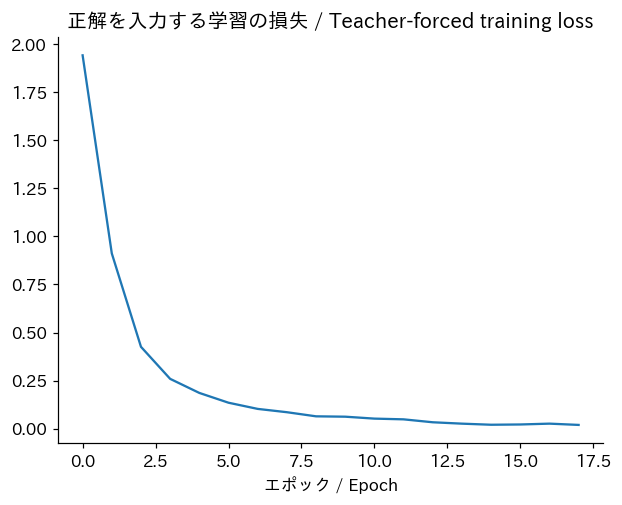

In [ ]:
history=[]
for epoch in range(EPOCHS):
    model.train();total=0
    for src,lengths,target in train_loader:
        src,target=src.to(device),target.to(device)
        optimizer.zero_grad();logits=model(src,lengths,target,TEACHER_FORCING)
        loss=F.cross_entropy(logits.reshape(-1,VOCAB),target.reshape(-1),ignore_index=PAD)
        loss.backward();nn.utils.clip_grad_norm_(model.parameters(),1.);optimizer.step();total+=loss.item()
    history.append(total/len(train_loader))
    if epoch==0 or (epoch+1)%3==0:print(f'エポック / Epoch {epoch+1}: 損失 / loss={history[-1]:.4f}')
plt.plot(history);plt.title('正解を入力する学習の損失 / Teacher-forced training loss');plt.xlabel('エポック / Epoch');plt.show()


## 評価と可視化 / Evaluation and visualization


In [ ]:
def decode(seq):
    result=[]
    for token in seq:
        if token==EOS:break
        if token>=3:result.append(str(token-3))
        else:result.append('<PAD>' if token==PAD else '<SOS>')
    return ' '.join(result)
model.eval();src,lengths,target=collate(test_samples);src,target=src.to(device),target.to(device)
with torch.no_grad():
    tf=model(src,lengths,target,1.0).argmax(-1)
    ar=model.generate(src,lengths).argmax(-1)
mask=target.ne(PAD)
print('正解入力時のトークン精度 / Teacher-forced token accuracy:',((tf==target)&mask).sum().item()/mask.sum().item())
print('自己回帰のトークン精度 / Autoregressive token accuracy:',((ar==target)&mask).sum().item()/mask.sum().item())
exact=np.mean([decode(a)==decode(b) for a,b in zip(ar.cpu().tolist(),target.cpu().tolist())])
print('自己回帰の系列完全一致率 / Autoregressive exact-sequence accuracy:',exact)
for i in range(8):
    print('入力 / Input:',decode(src[i].cpu().tolist()),'| 正解 / True:',decode(target[i].cpu().tolist()),'| 生成 / Generated:',decode(ar[i].cpu().tolist()))


正解入力時のトークン精度 / Teacher-forced token accuracy: 0.9949494949494949
自己回帰のトークン精度 / Autoregressive token accuracy: 0.9831649831649831
自己回帰の系列完全一致率 / Autoregressive exact-sequence accuracy: 0.97
入力 / Input: 9 7 5 2 9 <PAD> <PAD> | 正解 / True: 9 2 5 7 9 | 生成 / Generated: 9 2 5 7 9
入力 / Input: 0 0 1 3 1 8 9 | 正解 / True: 9 8 1 3 1 0 0 | 生成 / Generated: 9 1 8 3 0 1 0
入力 / Input: 8 1 7 <PAD> <PAD> <PAD> <PAD> | 正解 / True: 7 1 8 | 生成 / Generated: 7 1 8
入力 / Input: 0 4 8 9 <PAD> <PAD> <PAD> | 正解 / True: 9 8 4 0 | 生成 / Generated: 9 8 4 0
入力 / Input: 8 2 4 <PAD> <PAD> <PAD> <PAD> | 正解 / True: 4 2 8 | 生成 / Generated: 4 2 8
入力 / Input: 9 7 6 <PAD> <PAD> <PAD> <PAD> | 正解 / True: 6 7 9 | 生成 / Generated: 6 7 9
入力 / Input: 8 1 2 0 4 4 <PAD> | 正解 / True: 4 4 0 2 1 8 | 生成 / Generated: 4 4 0 2 1 8
入力 / Input: 6 0 7 <PAD> <PAD> <PAD> <PAD> | 正解 / True: 7 0 6 | 生成 / Generated: 7 0 6


## 評価と可視化 / Evaluation and visualization


In [ ]:
def try_sequence(text='1 2 3 4 5'):
    try: digits=[int(s) for s in text.split()]
    except ValueError: print('数字を空白で区切って入力してください． / Use space-separated digits.');return
    if not 1<=len(digits)<=MAX_LEN or any(v<0 or v>9 for v in digits):
        print(f'入力できる桁数 / Enter 1–{MAX_LEN}桁，各数字は0〜9 / digits, each 0–9.');return
    src,lengths,target=collate([([v+3 for v in digits],list(reversed([v+3 for v in digits]))+[EOS])])
    model.eval()
    result=model.generate(src.to(device),lengths).argmax(-1)[0].cpu().tolist()
    print('入力 / Input:',text,'| 期待する出力 / Expected:',' '.join(map(str,digits[::-1])),'| 生成 / Generated:',decode(result))
try_sequence()


入力 / Input: 1 2 3 4 5 | 期待する出力 / Expected: 5 4 3 2 1 | 生成 / Generated: 5 4 3 2 1


## インタラクティブ操作 / Interactive controls


In [ ]:
widgets.interact_manual.options(manual_name='実行 / Run')(try_sequence,text=widgets.Text(value='1 2 3 4 5',description='入力 / Input', style={'description_width':'initial'}, layout=widgets.Layout(width='auto',min_width='260px')))


interactive(children=(Text(value='1 2 3 4 5', description='入力 / Input', layout=Layout(min_width='260px', width…

<function __main__.try_sequence(text='1 2 3 4 5')>

## 観察・変更 / Observe and modify
- TEACHER_FORCINGを0.5にしてモデル定義・学習を再実行すると，学習にも自分の予測が入ります．必ず改善するとは限りません．
  Set TEACHER_FORCING to 0.5 and rerun model construction and training to sometimes feed predictions during training. Improvement is not guaranteed.
- 自己回帰精度とTeacher Forcing精度を区別してください．
  Distinguish autoregressive accuracy from teacher-forced accuracy.
- 1〜2桁は学習の長さ範囲外です．7桁を超える長さへの一般化はこの構成では検証していません．
  Inputs with 1–2 digits are outside the training length range. Generalization beyond seven digits is not evaluated here.


## 参考 / References
- [PyTorch documentation](https://docs.pytorch.org/docs/stable/nn.html)
- [scikit-learn: digits dataset](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_digits.html)
- [Colab widget example](https://colab.research.google.com/notebooks/snippets/advanced_outputs.ipynb)
